In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from datetime import datetime
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load and preprocess the dataset
def load_and_preprocess_data(filepath):
    df = pd.read_csv(filepath, delimiter=',')
    df['Time'] = pd.to_datetime(df['Time'])
    df.set_index('Time', inplace=True)
    df.sort_index(inplace=True)
    df_hourly = df.resample('h').mean()
    df_hourly['day_of_year'] = df_hourly['day_of_year'].astype(int)
    df_hourly['weekday'] = df_hourly['weekday'].astype(int)
    df_hourly['hour'] = df_hourly['hour'].astype(int)
    df_hourly['is_holiday'] = df_hourly['is_holiday'].astype(int)
    return df_hourly

# Make the time series data stationary 
def make_stationary(df, rolling_window):
    df['Parkings_rolling_mean'] = df['Parkings'].rolling(window=rolling_window).mean()
    df['Parkings_rolling_std'] = df['Parkings'].rolling(window=rolling_window).std()
    df['Parkings_stationary'] = (df['Parkings'] - df['Parkings_rolling_mean']) / df['Parkings_rolling_std']
    df.dropna(inplace=True)
    return df

# Split data into training and test sets
def split_data(df, end_date):
    train_data = df[df.index < end_date]
    test_data = df[df.index >= end_date]
    train_data.index = pd.DatetimeIndex(train_data.index.values, freq='h')
    return train_data, test_data

# Fit the SARIMA model
def fit_sarima_model(train_data, exogenous_features, order, seasonal_order):
    model = SARIMAX(train_data['Parkings_stationary'], 
                    order=order, 
                    seasonal_order=seasonal_order,
                    exog=train_data[exogenous_features])
    return model.fit()

# Predict using the fitted model
def make_predictions(model, test_data, exogenous_features):
    predictions_stationary = model.predict(start=test_data.index[0], end=test_data.index[-1], exog=test_data[exogenous_features], dynamic=False)
    predictions_rolling_mean_reversed = predictions_stationary * test_data['Parkings_rolling_std'] + test_data['Parkings_rolling_mean']
    return predictions_rolling_mean_reversed

# Calculate error metrics
def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

# Plot the results
def plot_results(train_data, test_data, predictions):
    plt.figure(figsize=(12, 6))
    plt.plot(train_data.index, train_data['Parkings'], label='Actual data', color='orange')
    plt.plot(test_data.index, test_data['Parkings'], color='orange')
    plt.plot(test_data.index, predictions, label='Predicted', color='green')
    plt.xlabel('Time')
    plt.ylabel('Parking Value')
    plt.title('SARIMA Parking Prediction')
    plt.legend()
    plt.show()


c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMA MAE: 196.21094142332242, RMSE: 243.2430102620836


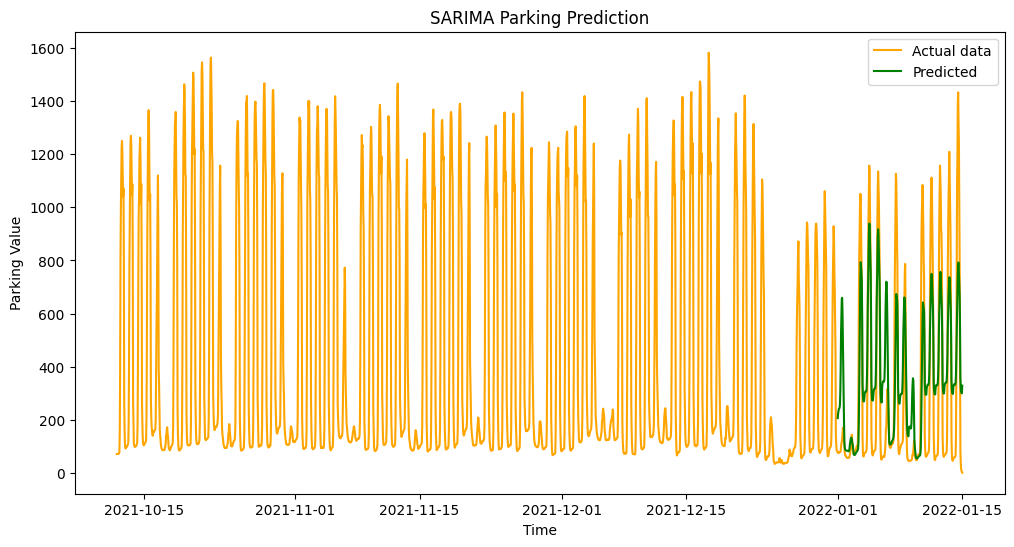

In [3]:
# Main script
if __name__ == "__main__":
    filepath = '../data/parking_time_series_with_features_1_hour.csv' # Using 1 hour data for SARIMA because shorter sampling intervals gave worse results
    df_hourly = load_and_preprocess_data(filepath)
    df_hourly = make_stationary(df_hourly, rolling_window=24)
    end_date = datetime(2022, 1, 1)
    train_data, test_data = split_data(df_hourly, end_date)
    exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]
    sarima_order = (4, 0, 2)
    seasonal_order = (1, 0, 1, 24)
    sarima_model = fit_sarima_model(train_data, exogenous_features, sarima_order, seasonal_order)
    predictions = make_predictions(sarima_model, test_data, exogenous_features)
    mae, rmse = calculate_metrics(test_data['Parkings'], predictions)
    print(f'SARIMA MAE: {mae}, RMSE: {rmse}')
    plot_results(train_data, test_data, predictions)